In [1]:
import sys
sys.path.append('../Utils')
sys.path.append('../Data')
sys.path.insert(0, '../../FRLC/src/')

from objective import solve_V_all_slices
from simulations import create_realistic_data, visualize_all
from plot_utils import plot_slices_horizontal_centered, plot_mass_transport_heatmap, plot_gene_panels, panel
from impute import impute_slice_fgw_barycenter, align_by_pca
from metrics import cluster_compute_ari_and_plot
from prepare_aging import prepare_data

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.optimize import minimize_scalar

import torch

if False:#torch.cuda.is_available():
    from objective_cuda import solve_V_all_slices_torch as solve_V_all_slices
else:
    from objective import solve_V_all_slices


%load_ext autoreload
%autoreload 2

In [2]:
data_dir = "../../../Data/Aging"
adata_all, pd_B, timepoints = prepare_data(data_dir=data_dir, reference='cells')

/home/zhaow/ST-CARD/GitRepo/Scripts/../Data/prepare_aging.py:134: FutureWarning: The function read_loom is deprecated and will be removed in the future. Deprecated in favor of other formats, e.g. (`write_h5ad` and then) `read_h5ad`. Loom isn’t well-maintained and supports only a subset of anndata features.
  ref_obj = sc.read_loom(os.path.join(data_dir, "l5_all.agg.loom"))
/home/zhaow/miniforge3/lib/python3.13/site-packages/anndata/_io/read.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  axis_df[k] = v
/home/zhaow/miniforge3/lib/python3.13/site-packages/anndata/_io/read.py:163: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns 

In [17]:
seed = 0
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

V, pi, aux = solve_V_all_slices(
                        adata_all, pd_B,
                        lam=0e0, mu=1e1, 
                        verbose=True,
                        ot_solver='low_rank',
                        alpha = 0.5,
                        k=100, 
                        sparsify = True
                    )

iter    0  f=8.301511e+07  rel_drop=1.000e+00  mean step=5.16e-09
iter   50  f=6.219021e+07  rel_drop=9.410e-05  mean step=3.74e-09


KeyboardInterrupt: 

In [16]:
pd_B.shape

(39, 258)

In [12]:
import anndata as ad
import matplotlib.pyplot as plt
ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_all),
            celltype_key="celltype",
            embedding_key="spatial",
            clustering="leiden",
            plot=False, 
            auto_resolution=True,
            # resolution_grid = np.linspace(0.01, 0.5, 3)

) 

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_all])
for i, adt in enumerate(adata_all):
    adt.obs['pred_label_matchk'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))


ari, nmi, true_labels, pred_labels = cluster_compute_ari_and_plot(
            np.vstack(V),
            ad.concat(adata_all),
            celltype_key="celltype",
            embedding_key="spatial",
            clustering="leiden",
            plot=False, 
            auto_resolution=False,
            # resolution_grid = np.linspace(0.01, 0.5, 3)

) 

n_spots = np.cumsum([0] + [adt.n_obs for adt in adata_all])
for i, adt in enumerate(adata_all):
    adt.obs['pred_label'] = pd.Categorical(pred_labels[n_spots[i]:n_spots[i + 1]])

print('ari='+str(ari))
print('nmi='+str(nmi))

clustering at resolution=1.0 has been done! Found 34 clusters.
Leiden: resolution=1.000, n_clusters=34
ari=0.3011829432391365
nmi=0.6128165538456404


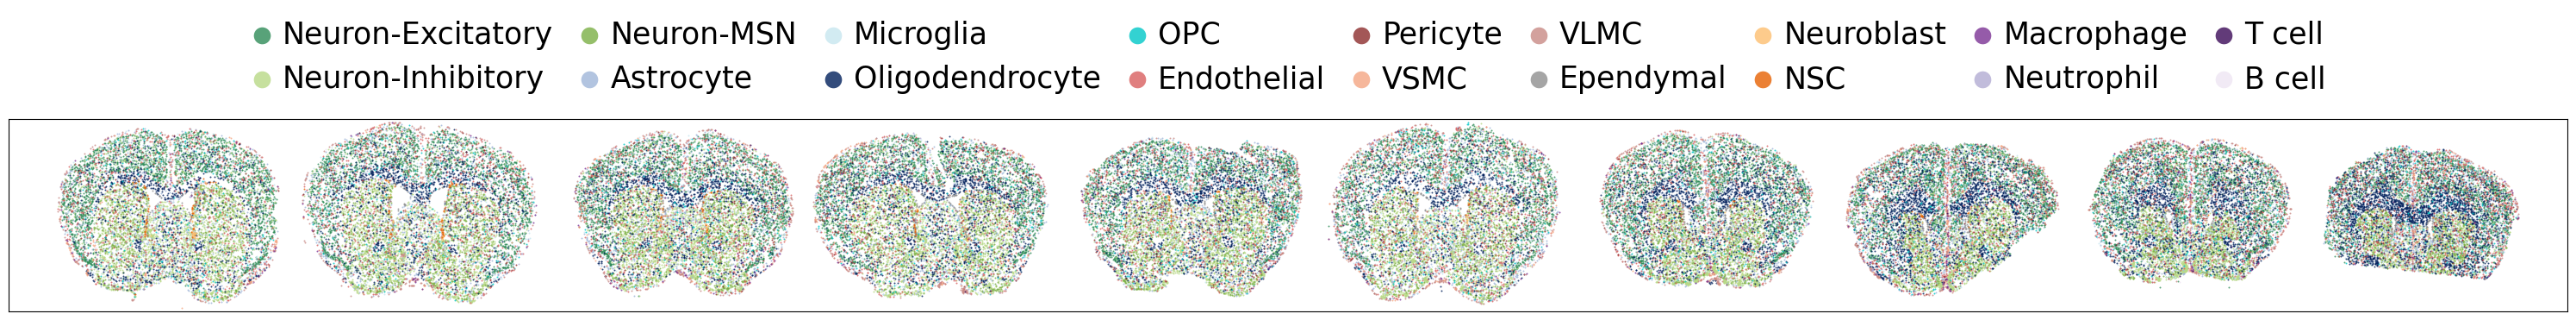

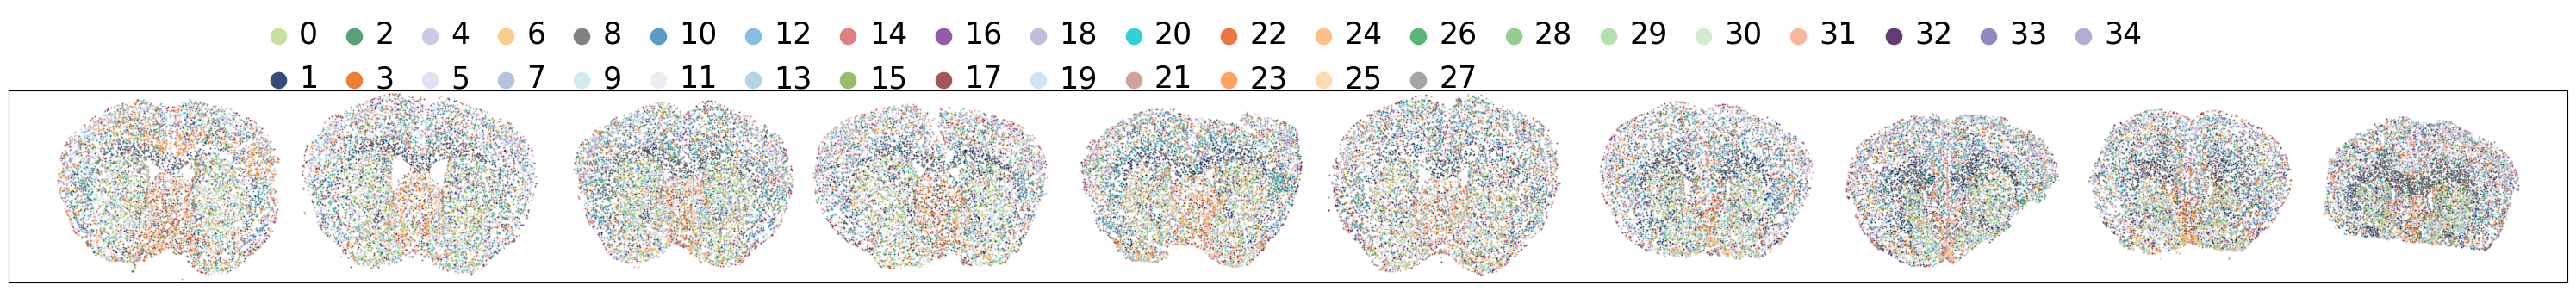

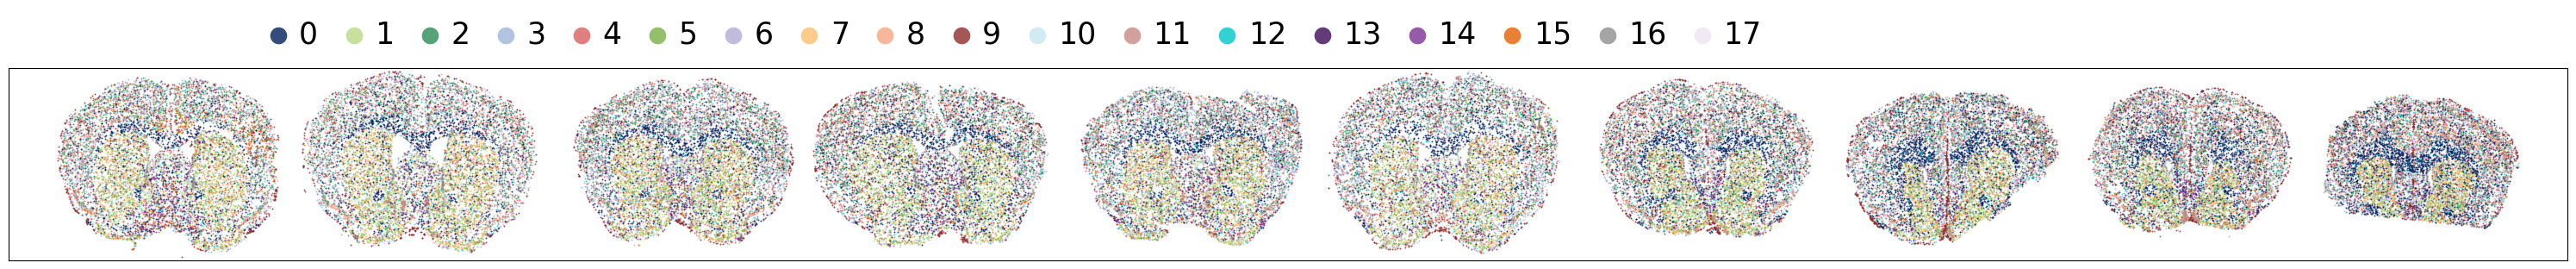

In [ ]:


import matplotlib.colors as mcolors
cell_type_colors = {
    # Neurons — keep layer / anatomical structure visible
    "Neuron-Excitatory": "#2E8B57",  # medium green
    "Neuron-Inhibitory": "#B8D986",  # pale yellow-green
    "Neuron-MSN":        "#7BAF45",  # olive green for striatum

    # Glia — Oligo/OPC emphasized
    "Astrocyte":         "#9FB6D9",  # muted pale blue
    "Microglia":         "#C7E7EF",  # very pale cyan
    "Oligodendrocyte":   "#001F5B",
    "OPC":               "#00C7C7",  # bright teal

    # Vasculature — visible but less dominant
    "Endothelial":       "#D95F5F",
    "Pericyte":          "#8C2D2D",
    "VSMC":              "#F4A582",
    "VLMC":              "#C98A85",

    # Other structural
    "Ependymal":         "#8F8F8F",

    # Neurogenic — orange but not too loud
    "Neuroblast":        "#FDBF6F",
    "NSC":               "#E66101",

    # Immune — push into background except macrophage
    "Macrophage":        "#7B3294",
    "Neutrophil":        "#B2ABD2",
    "T cell":            "#3B0A57",#"#D8C6E6",
    "B cell":            "#EEE5F3",
}

cell_types = list(cell_type_colors.keys())
colors_18  = list(cell_type_colors.values())
cmap = mcolors.ListedColormap(colors_18, name="brain_celltypes")

for t in range(len(adata_all)):
    adata_all[t].obs['x'], adata_all[t].obs['y'] = adata_all[t].obsm['spatial'][:,0], adata_all[t].obsm['spatial'][:,1]

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[0::2],
    obs_key="celltype",
    obsm_key="spatial",         
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend_loc='upper center',
    legend_bbox=(0.5,0.9),
    legend_ncol = 9,
    legend_font=25,
    truth_key="celltype",
    truth_cmap=cmap,
    legend_markerscale=10,
    # highlight_labels=['Oligodendrocyte','OPC']
)
plt.show()

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[0::2],
    obs_key="pred_label",
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend=True,
    legend_bbox=(0.1,0.75),
    legend_ncol = 21,
    legend_font=25,
    truth_key="celltype",
    truth_cmap=cmap,
    legend_markerscale=10,
)
plt.show()

fig, ax = plot_slices_horizontal_centered(
    adata_list=adata_all[0::2],
    obs_key="pred_label_matchk",
    obsm_key="spatial",         # otherwise uses ad.obsm['spatial'][:, :2]
    y_scale=1.0,
    x_gap = 1050,
    s=2,
    alpha = 0.8,
    legend=True,
    legend_bbox=(0.1,0.75),
    legend_ncol = 21,
    legend_font=25,
    truth_key="celltype",
    truth_cmap=cmap,
    legend_markerscale=10,
)
plt.show()


# Some downstream analysis

In [14]:
from plot_utils import plot_V_dotplot_from_adata
from downstream import region_de_wilcoxon, clean_gene_for_enrichr, plot_gene_lollipop_by_region
from downstream import make_gene_name_table, add_parsed_gene_names_to_de

## Task 1 (straightforward): temporal variation in the population and cell type program magnitude varying over time

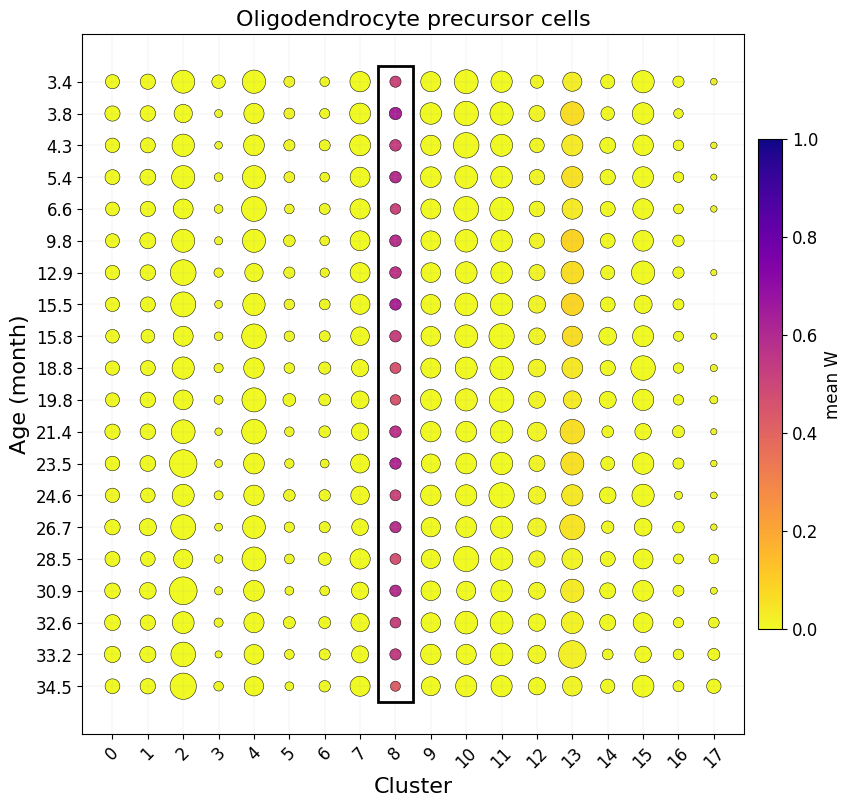

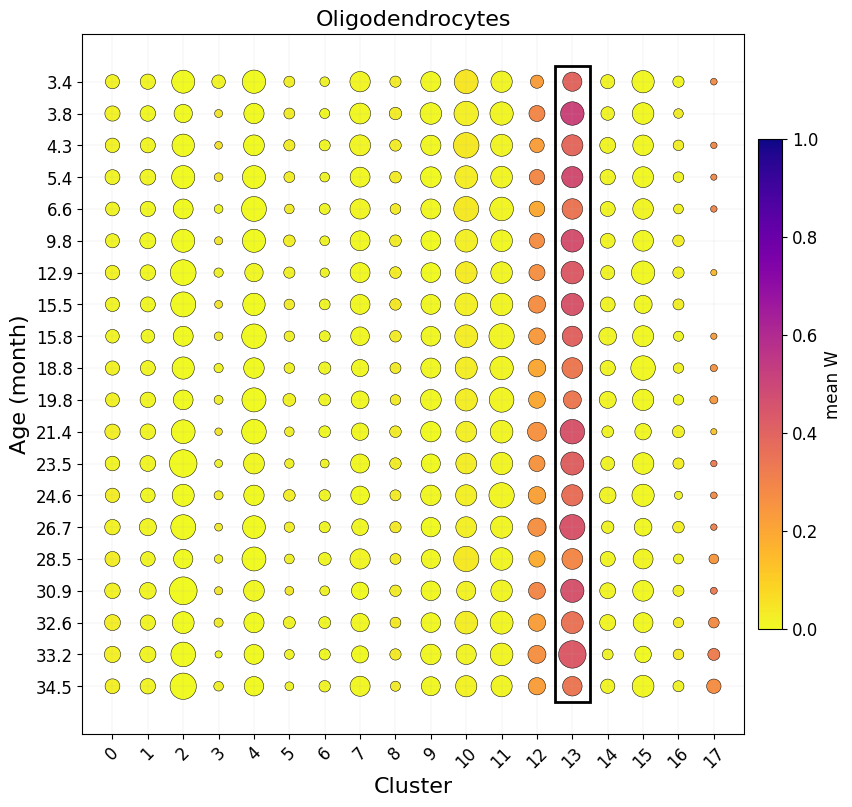

In [15]:
plt.rcParams['font.size'] = 12
celltype_order = pd_B.index.to_list()

fig = plt.figure(figsize=(10,10))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])   # [left, bottom, width, height]

fig = plot_V_dotplot_from_adata(
    adata_list=adata_all,
    V_list=V,
    celltype="Oligodendrocyte precursor cells",
    celltype_names=celltype_order,
    region_key="pred_label_matchk",
    times=[str(t) for t in timepoints],
    agg="mean",
    cmap="plasma_r",
    ax = ax,
    time_name = 'Age (month)',
    box_threshold = 0.3
)

fig = plt.figure(figsize=(10,10))
ax = fig.add_axes([0.15, 0.15, 0.7, 0.7])   # [left, bottom, width, height]

fig = plot_V_dotplot_from_adata(
    adata_list=adata_all,
    V_list=V,
    celltype="Oligodendrocytes",
    celltype_names=celltype_order,
    region_key="pred_label_matchk",
    times=[str(t) for t in timepoints],
    agg="mean",
    cmap="plasma_r",
    ax = ax,
     time_name = 'Age (month)',
     box_threshold = 0.3
)

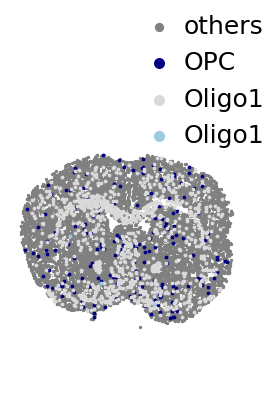

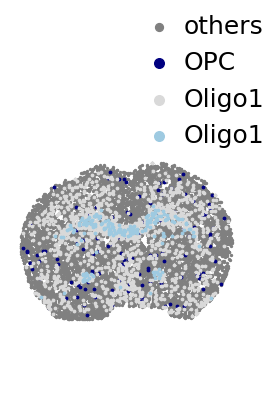

In [ ]:
plt.rcParams['figure.figsize'] = (3,4)
cmap = plt.get_cmap("tab20c")
colors = cmap(np.linspace(0, 11/20, 20))

regions_of_interest = [12, 0,17]#[23, 7, 17]#[22, 0, 29]
for t in [0, 19]:
    # adata_all[t].obs['x'], adata_all[t].obs['y'] = adata_all[t].obsm['spatial'][:,0], adata_all[t].obsm['spatial'][:,1]
    plt.scatter(adata_all[t].obs['x'], adata_all[t].obs['y'], c='gray', s=2, label='others')

    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == regions_of_interest[0]].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == regions_of_interest[0]].obs['y'], s=3,  color="#000080",  label='OPC')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == regions_of_interest[1]].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == regions_of_interest[1]].obs['y'], s=3,  color="#d9d9d9", label='Oligo1')
    # plt.scatter(adata_all[t][adata_all[t].obs["pred_label"] == regions_of_interest[2]].obs['x'], adata_all[t][adata_all[t].obs["pred_label"] == regions_of_interest[2]].obs['y'], s=3,  color="#9ecae1",  label='Oligo2')
    
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[0]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[0]].obs['y'], s=3,  color="#000080",  label='OPC')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[1]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[1]].obs['y'], s=3,  color="#d9d9d9", label='Oligo1')
    plt.scatter(adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[2]].obs['x'], adata_all[t][adata_all[t].obs["pred_label_matchk"] == regions_of_interest[2]].obs['y'], s=3,  color="#9ecae1", label='Oligo1')
   


    plt.axis('equal')
    plt.axis('off')
    plt.legend(
        frameon=False,
        fontsize=18,
        markerscale=4,      # makes legend dots larger
        handlelength=1.2,
        handletextpad=0.4,
        borderpad=0.2,
        labelspacing=0.5,
        loc="center left",
        bbox_to_anchor=(0.5, 1.02),
        ncol=1
    )
    # plt.title(str(time[t])+' Mon')
    plt.show()

In [ ]:
de_df = region_de_wilcoxon(
    ad.concat(adata_all),
    region_key="pred_label_matchk",
    layer=None,
    min_region_size=10,
    min_frac=0.05,
    genes = pd_B.columns
)

Renormalizing from layers['counts'] (target_sum=10000, log1p for tests).
  Testing 260 of the supplied genes.
Computing region 0...
Computing region 1...
Computing region 2...
Computing region 3...
Computing region 4...
Computing region 5...
Computing region 6...
Computing region 7...
Computing region 8...
Computing region 9...
Computing region 10...
Computing region 11...
Computing region 12...
Computing region 13...
Computing region 14...
Computing region 15...
Computing region 16...
Computing region 17...


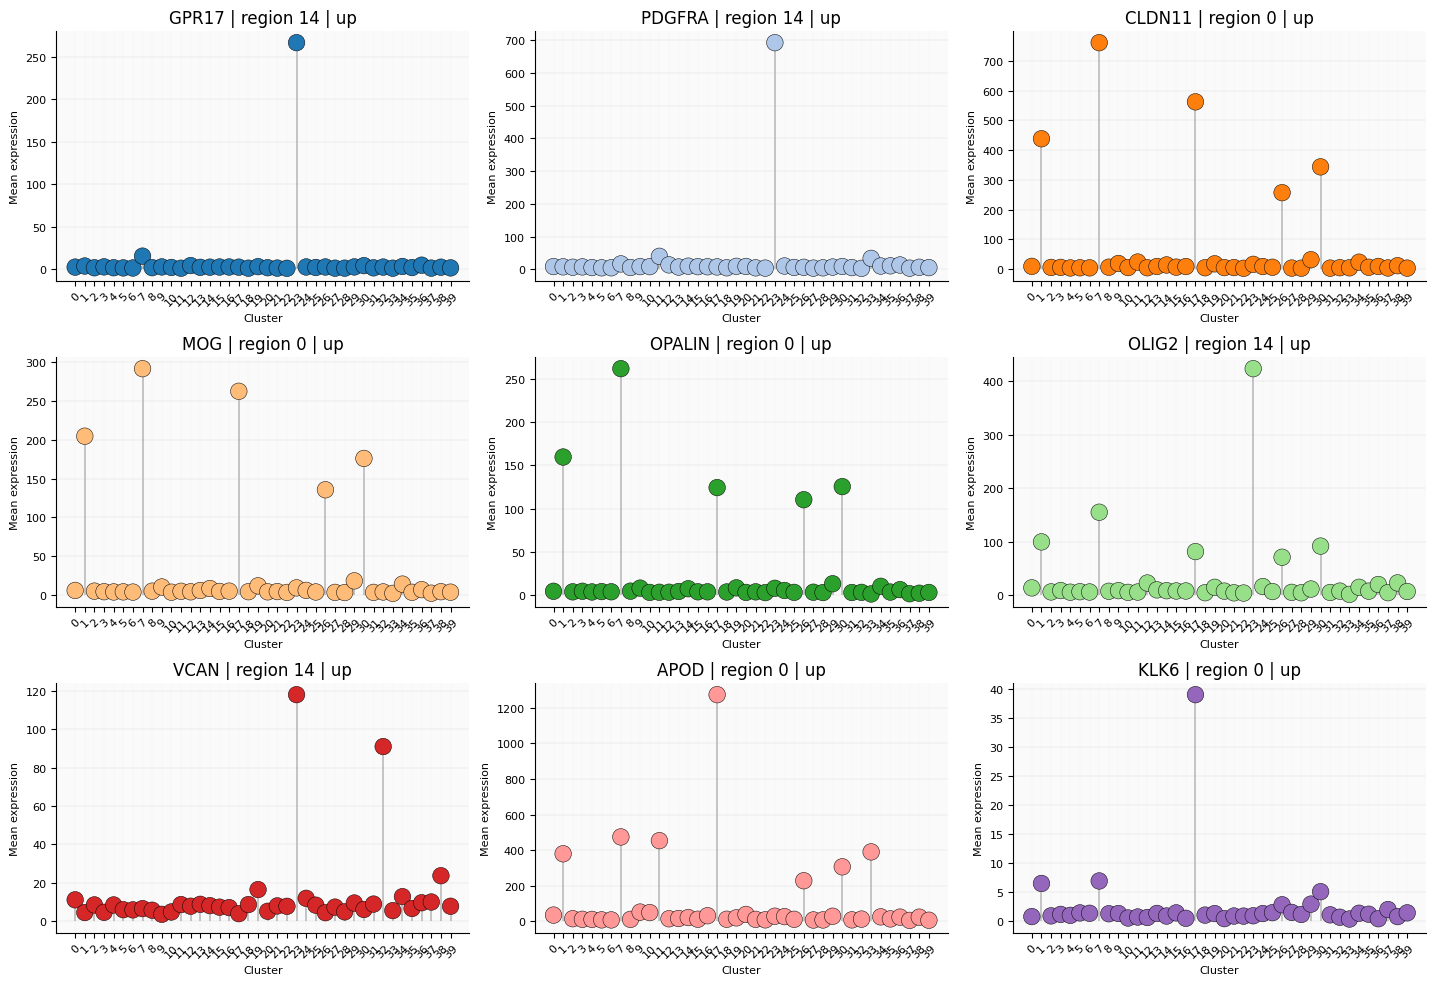

In [ ]:
gene_table = make_gene_name_table(de_df["gene"].unique())
de_df_go = add_parsed_gene_names_to_de(de_df)
plt.rcParams['font.size'] = 8
# regions_of_interest = ['0', '13', '14'] # This may change; I selected domains from the dotplot with dominant colors

regions_of_interest = [str(t) for t in regions_of_interest]#['0', '22', '29'] # This may change; I selected domains from the dotplot with dominant colors


top = (
    de_df_go
    .assign(region=lambda d: d["region"].astype(str),
            abs_log2fc=lambda d: d["log2fc"].abs(),
            direction=lambda d: np.where(d["log2fc"] >= 0, "up", "down"))
    .query("region in @regions_of_interest and p_adj < 0.05 and log2fc > 0.25")
    .sort_values(["p_adj", "log2fc"], ascending=[True, False])
    .drop_duplicates("gene")
    .head(9)
    .set_index("gene")
)

top["label"] = (top["human_symbol"].fillna(pd.Series(top.index, index=top.index))
                .map(clean_gene_for_enrichr)
                .fillna(pd.Series(top.index, index=top.index)))

fig, axes, df = plot_gene_lollipop_by_region(
    ad.concat(adata_all),
    genes=top.index.tolist(),
    region_key="pred_label",
    color_by="gene",
    gene_direction_map=top["direction"].to_dict(),
    gene_region_map=top["region"].to_dict(),
    gene_label_map=top["label"].to_dict(),
)
plt.show()

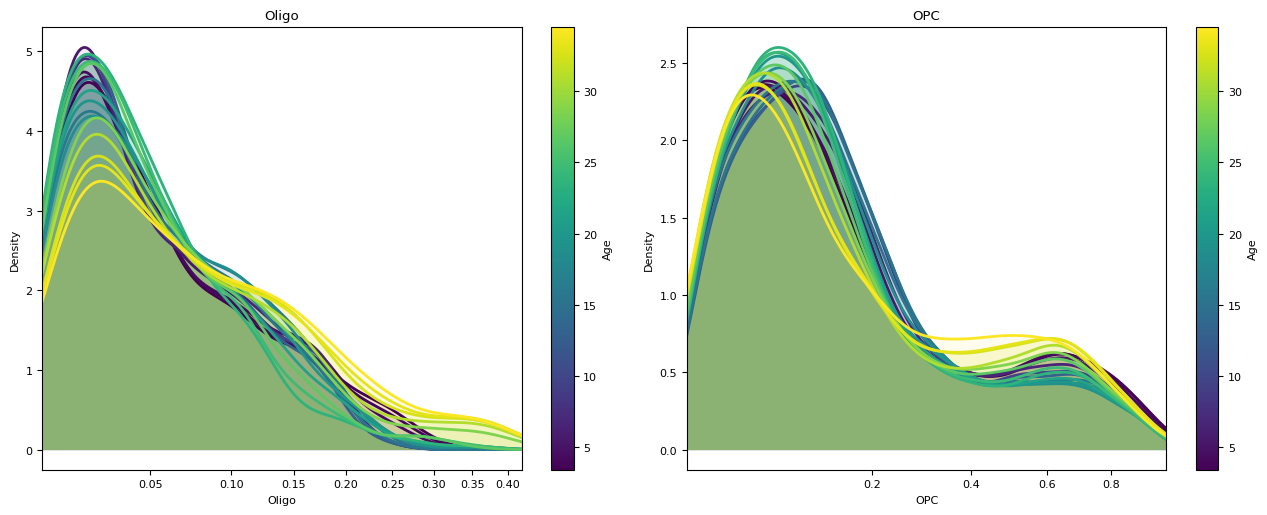

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.stats import gaussian_kde


def normalize_V(V):
    """Row-normalize so each spot's cell-type coefficients sum to 1."""
    V = np.asarray(V, dtype=float)
    return V / (np.sum(V, axis=1, keepdims=True) + 1e-12)


def plot_nonzero_V_histograms_on_ax(
    ax,
    times,
    V_list,
    celltype_idx,
    name,
    region_masks=None,
    eps=1e-8,
    density=True,
    cmap="viridis",
    x_quantile=0.995,
    use_kde=True,
    bandwidth=None,
    smooth_window=3,
    fill_alpha=0.08,
    xscale="sqrt",
    show_colorbar=True,
):
    """Distribution of nonzero V coefficients for one cell type across time.

    Rows are normalized over all cell types first, so a value is that type's
    share of its spot. `region_masks` — one boolean array per timepoint, in the
    same order as `V_list` — then restricts to a subset of spots; the
    normalization still spans every type, so the values keep their meaning.

    KDE is fit in the transformed x-space, so the curves are correct rather
    than merely redrawn when `xscale` is "sqrt" or "log".

    `smooth_window` pools neighbouring timepoints with Gaussian weights to
    stabilize the estimate — set to 1 for no pooling.

    Returns (values per timepoint, per-timepoint summary dicts).
    """
    times_arr = np.asarray(times, dtype=float)
    order = np.argsort(times_arr)
    times_sorted = times_arr[order]
    V_sorted = [V_list[i] for i in order]
    masks_sorted = (
        [None] * len(V_sorted) if region_masks is None
        else [np.asarray(region_masks[i], bool) for i in order]
    )

    if xscale == "sqrt":
        fwd, inv = np.sqrt, lambda u: u ** 2
    elif xscale == "log":
        fwd, inv = np.log10, lambda u: 10 ** u
    elif xscale == "linear":
        fwd = inv = lambda x: x
    else:
        raise ValueError("xscale must be 'linear', 'sqrt', or 'log'.")

    # ── Values per timepoint, after masking ──────────────────────────────
    vals_by_time, n_spots = [], []
    for Vi, m in zip(V_sorted, masks_sorted):
        vals = normalize_V(Vi)[:, celltype_idx]
        if m is not None:
            if len(m) != len(vals):
                raise ValueError(
                    f"mask length {len(m)} != {len(vals)} spots in this slice."
                )
            vals = vals[m]
        n_spots.append(len(vals))

        vals = np.asarray(vals, float)
        vals_by_time.append(vals[np.isfinite(vals) & (vals > eps)])

    nonempty = [v for v in vals_by_time if len(v) > 0]
    if not nonempty:
        raise ValueError(f"No nonzero values found for {name} with eps={eps}")

    all_vals = np.concatenate(nonempty)
    lo = float(np.min(all_vals))
    hi = float(np.quantile(all_vals, x_quantile))

    u_lo, u_hi = fwd(lo), fwd(hi)
    u_pad = 0.05 * (u_hi - u_lo + 1e-12)
    u_grid = np.linspace(u_lo, u_hi + u_pad, 400)
    x_grid = inv(u_grid)
    x_max = inv(u_hi + u_pad)

    norm = Normalize(vmin=times_sorted.min(), vmax=times_sorted.max())
    cmap_obj = plt.get_cmap(cmap)

    half = max(0, smooth_window // 2)
    sigma = max(1.0, half)
    n_t = len(times_sorted)
    summaries = []

    for i, t in enumerate(times_sorted):
        if len(vals_by_time[i]) == 0:
            continue

        # Pool neighbouring timepoints, weighted by distance in index.
        pooled, weights = [], []
        for j in range(max(0, i - half), min(n_t, i + half + 1)):
            if len(vals_by_time[j]) == 0:
                continue
            w = np.exp(-0.5 * ((j - i) / sigma) ** 2)
            pooled.append(vals_by_time[j])
            weights.append(np.full(len(vals_by_time[j]), w))

        if not pooled:
            continue

        vals_pooled = np.concatenate(pooled)
        weights_pooled = np.concatenate(weights)
        keep = (vals_pooled >= lo) & (vals_pooled <= x_max)
        vals_pooled, weights_pooled = vals_pooled[keep], weights_pooled[keep]

        if len(vals_pooled) < 2:
            continue

        color = cmap_obj(norm(t))
        u_pooled = fwd(vals_pooled)

        if use_kde and np.std(u_pooled) > 1e-12:
            try:
                kde = gaussian_kde(
                    u_pooled, bw_method=bandwidth, weights=weights_pooled
                )
            except TypeError:      # older scipy has no weights argument
                kde = gaussian_kde(u_pooled, bw_method=bandwidth)
            y = kde(u_grid)
            ax.fill_between(x_grid, y, color=color, alpha=fill_alpha, linewidth=0)
            ax.plot(x_grid, y, color=color, linewidth=2, label=f"{t:g}")

        summaries.append({
            "time": float(t),
            "n_spots": n_spots[i],
            "n_nonzero": int(len(vals_by_time[i])),
            "nonzero_prop": len(vals_by_time[i]) / max(n_spots[i], 1),
            "mean_nonzero": float(np.mean(vals_by_time[i])),
            "median_nonzero": float(np.median(vals_by_time[i])),
        })

    if xscale == "sqrt":
        ax.set_xscale("function", functions=(np.sqrt, np.square))
    elif xscale == "log":
        ax.set_xscale("log")

    ax.set_xlim(lo, x_max)
    ax.set_xlabel(name)
    ax.set_ylabel("Density")
    ax.set_title(name)

    if show_colorbar:
        sm = ScalarMappable(norm=norm, cmap=cmap_obj)
        sm.set_array([])
        plt.colorbar(sm, ax=ax).set_label("Age")

    return vals_by_time, summaries


def region_masks_from_obs(adata_list, region, key="pred_label"):
    """Boolean mask per slice selecting spots whose `key` equals `region`."""
    return [
        (a.obs[key].astype(str) == str(region)).to_numpy()
        for a in adata_list
    ]

# masks = region_masks_from_obs(adata_all, region="0")
# print([m.sum() for m in masks])   # check the region exists at every timepoint

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

oligo_vals, oligo_summary = plot_nonzero_V_histograms_on_ax(
    axes[0], times=timepoints, V_list=V, celltype_idx=2, name="Oligo",
    region_masks=None, eps=1e-2, smooth_window=5, xscale="sqrt",
)
opc_vals, opc_summary = plot_nonzero_V_histograms_on_ax(
    axes[1], times=timepoints, V_list=V, celltype_idx=17, name="OPC",
    region_masks=None, eps=1e-2, smooth_window=5, xscale="sqrt",
)
plt.tight_layout()

In [ ]:
import anndata as ad
adata_cat = ad.concat(adata_all)
comp = pd.DataFrame({
    reg: adata_cat.obs.loc[
        adata_cat.obs["pred_label_matchk"].astype(str) == reg, "celltype"
    ].astype(str).value_counts(normalize=True)
    for reg in regions_of_interest#["0", "13", "14"]
}).fillna(0)

print((comp * 100).round(1).to_string())

import anndata as ad
adata_cat = ad.concat(adata_all)
comp = pd.DataFrame({
    reg: adata_cat.obs.loc[
        adata_cat.obs["pred_label_matchk"].astype(str) == reg, "celltype"
    ].astype(str).value_counts(normalize=False)
    for reg in regions_of_interest#["0", "13", "14"]
}).fillna(0)

print((comp).round(1).to_string())

                      0    14
celltype                     
Astrocyte           0.5   0.0
B cell              0.0   0.0
Endothelial         0.6   0.5
Ependymal           0.0   0.0
Macrophage          0.0   0.0
Microglia           0.5   0.1
NSC                 0.0   0.0
Neuroblast          0.0   0.1
Neuron-Excitatory   0.1   0.1
Neuron-Inhibitory   0.3   0.6
Neuron-MSN          0.0   0.0
Neutrophil          0.0   0.0
OPC                 1.2  97.5
Oligodendrocyte    96.2   0.8
Pericyte            0.2   0.2
T cell              0.0   0.0
VLMC                0.3   0.0
VSMC                0.0   0.0
                       0      14
celltype                        
Astrocyte            145     1.0
B cell                 2     1.0
Endothelial          161    19.0
Ependymal              5     1.0
Macrophage             1     1.0
Microglia            138     2.0
NSC                   10     1.0
Neuroblast            12     3.0
Neuron-Excitatory     42     3.0
Neuron-Inhibitory    101    21.0
Neur

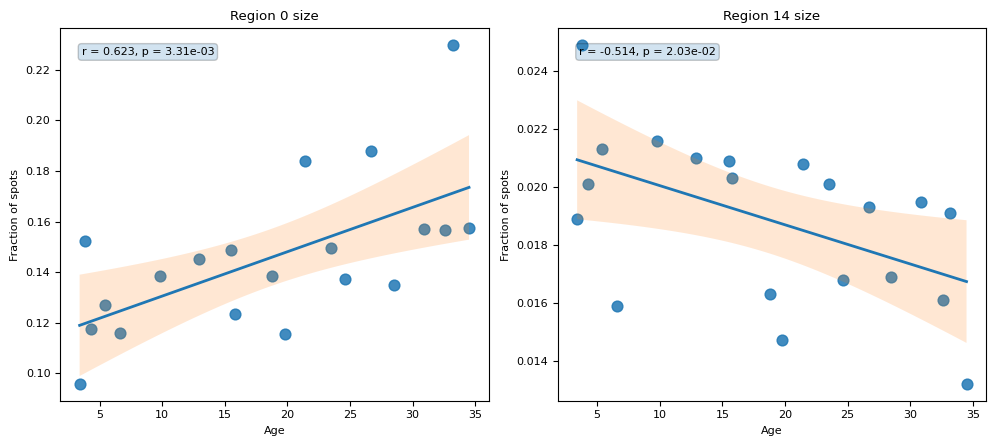

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, t as t_dist


def fit_ci_band(x, y, x_fit, alpha=0.05):
    """Confidence interval for the fitted regression mean line."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    n = len(x)
    if n <= 2:
        y_fit = np.poly1d(np.polyfit(x, y, deg=1))(x_fit)
        return y_fit, y_fit, y_fit

    fit_fn = np.poly1d(np.polyfit(x, y, deg=1))
    y_fit = fit_fn(x_fit)
    s_err = np.sqrt(np.sum((y - fit_fn(x)) ** 2) / (n - 2))
    x_mean = np.mean(x)
    sxx = np.sum((x - x_mean) ** 2)
    t_crit = t_dist.ppf(1 - alpha / 2, df=n - 2)
    ci = t_crit * s_err * np.sqrt(1 / n + (x_fit - x_mean) ** 2 / sxx)
    return y_fit, y_fit - ci, y_fit + ci


def plot_region_size_on_ax(ax, times, adata_list, region,
                           region_key="pred_label", name=None,
                           as_fraction=True, xlabel="Age"):
    """Region size across time. as_fraction divides by slice size, which
    matters when slices differ in total spot count."""
    times_arr = np.asarray(times, float)
    name = name or f"Region {region}"

    counts = np.array([
        int((a.obs[region_key].astype(str) == str(region)).sum())
        for a in adata_list
    ], float)
    totals = np.array([a.n_obs for a in adata_list], float)

    y = counts / np.maximum(totals, 1) if as_fraction else counts

    x_fit = np.linspace(times_arr.min(), times_arr.max(), 200)
    y_fit, lo, hi = fit_ci_band(times_arr, y, x_fit)
    r, p = pearsonr(times_arr, y)

    ax.scatter(times_arr, y, s=60, alpha=0.85)
    ax.plot(x_fit, y_fit, linewidth=2)
    ax.fill_between(x_fit, lo, hi, alpha=0.18)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Fraction of spots" if as_fraction else "Number of spots")
    ax.set_title(f"{name} size")
    ax.text(0.05, 0.95, f"r = {r:.3f}, p = {p:.2e}", transform=ax.transAxes,
            verticalalignment="top", bbox=dict(boxstyle="round", alpha=0.2))

    return {"region": region, "counts": counts, "totals": totals,
            "y": y, "r": r, "p": p}


# regions = ["0", "13", "14"]
fig, axes = plt.subplots(1, len(regions_of_interest), figsize=(5 * len(regions_of_interest), 4.5), sharex=True)
results = [
    plot_region_size_on_ax(ax, timepoints, adata_all, reg, region_key = "pred_label_matchk")
    for ax, reg in zip(np.atleast_1d(axes), regions_of_interest)
]
plt.tight_layout()

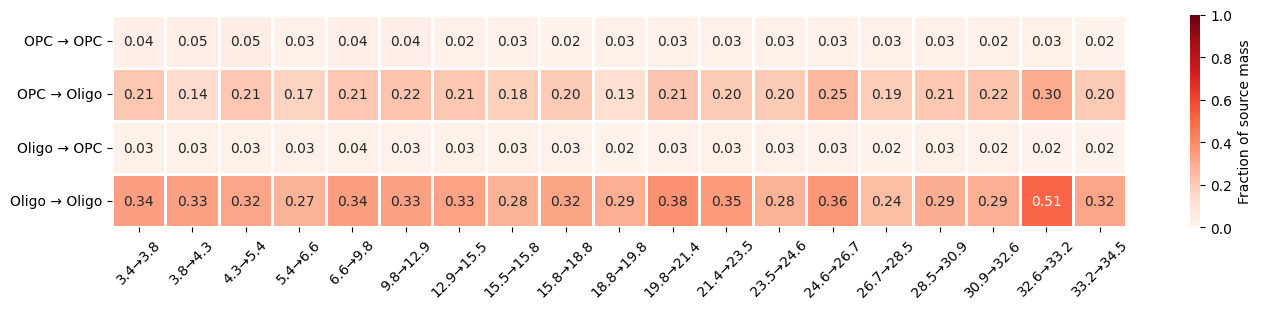

In [ ]:
from downstream import compute_transition_tables_from_couplings, add_cluster_annotation_from_V
import seaborn as sns
# regions = ["0", "13", "14"]

regions_of_interest_str = ["Oligodendrocyte precursor cells", "Oligodendrocytes"]
edges = [(s, t) for s in regions_of_interest_str for t in regions_of_interest_str]
edge_names = ["OPC → OPC", "OPC → Oligo", "Oligo → OPC", "Oligo → Oligo"]

# 19 intervals for 20 timepoints; label by the bracketing times
intervals = [f"{a:g}→{b:g}" for a, b in zip(timepoints[:-1], timepoints[1:])]


adata_cat = ad.concat(adata_all)
V_cat = np.vstack([v / v.sum(axis=1, keepdims=True) for v in V])

adata_cat = add_cluster_annotation_from_V(
    adata_cat, V_cat, celltype_order=celltype_order,
    cluster_key="pred_label", key_added="cluster_annotated_celltype",
)

lut = (adata_cat.obs[["pred_label", "cluster_annotated_celltype"]]
       .drop_duplicates().set_index("pred_label")["cluster_annotated_celltype"])

for a in adata_all:
    a.obs["cluster_annotated_celltype"] = a.obs["pred_label"].map(lut).astype("category")

tables, _ = compute_transition_tables_from_couplings(
    adata_all, pi, celltype_key="cluster_annotated_celltype", normalize="total"
)

# NaN where the source is absent, so it's distinct from "went nowhere"
frac = [t.div(t.sum(axis=1).replace(0, np.nan), axis=0) for t in tables]
df = pd.DataFrame(
    [[f.loc[s, tg] if s in f.index and tg in f.columns else np.nan
      for s, tg in edges] for f in frac],
    index=intervals, columns=edge_names,
).T

plt.rcParams['font.size'] = 10
fig, ax = plt.subplots(figsize=(14, 3.2))
sns.heatmap(df.fillna(0), ax=ax, cmap="Reds", vmin=0, vmax=1,
            annot=df.map(lambda v: "Absent" if pd.isna(v) else f"{v:.2f}"),
            fmt="", linewidths=1, linecolor="white",
            cbar_kws={"label": "Fraction of source mass"})
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

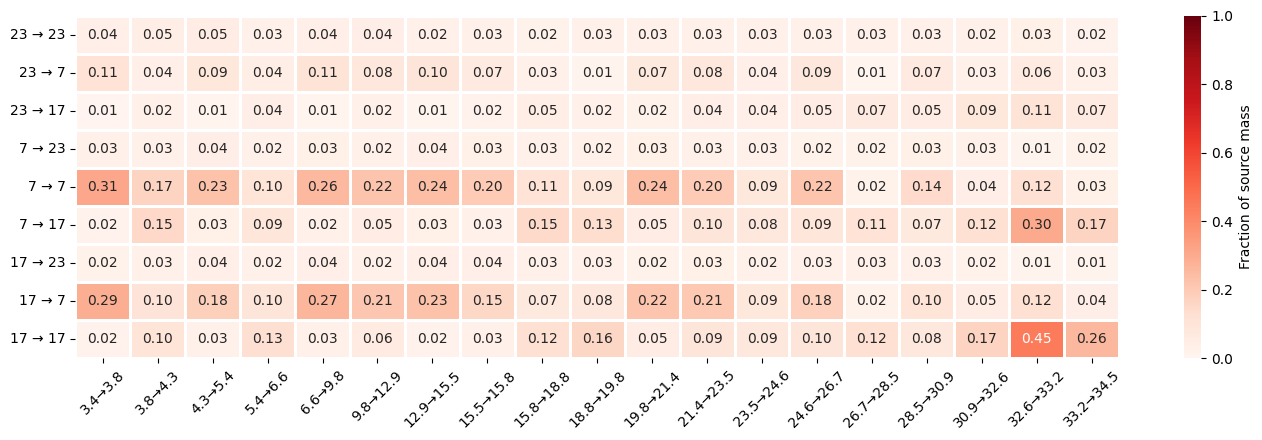

In [ ]:
from downstream import compute_transition_tables_from_couplings
import seaborn as sns


edges = [(s, t) for s in regions_of_interest for t in regions_of_interest]
edge_names = [f"{s} → {t}" for s, t in edges]

intervals = [f"{a:g}→{b:g}" for a, b in zip(timepoints[:-1], timepoints[1:])]

tables, _ = compute_transition_tables_from_couplings(
    adata_all, pi, celltype_key="pred_label", normalize="total"
)

# NaN where the source is absent, so it's distinct from "went nowhere"
frac = [t.div(t.sum(axis=1).replace(0, np.nan), axis=0) for t in tables]
df = pd.DataFrame(
    [[f.loc[s, tg] if s in f.index and tg in f.columns else np.nan
      for s, tg in edges] for f in frac],
    index=intervals, columns=edge_names,
).T

plt.rcParams['font.size'] = 10
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(df.fillna(0), ax=ax, cmap="Reds", vmin=0, vmax=1,
            annot=df.map(lambda v: "Absent" if pd.isna(v) else f"{v:.2f}"),
            fmt="", linewidths=1, linecolor="white",
            cbar_kws={"label": "Fraction of source mass"})
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()